# TV4 · LAB EDA — MỤC 1.1: THỐNG KÊ MÔ TẢ
**Bản sửa lỗi đọc CSV cho VS Code:** đặt `covid-data.csv`, `marketing_campaign.csv`, `winequality-red.csv`, `diabetes.csv` vào thư mục `Tuan05/PTKPDL/data`. CSV Diabetes có thể được đọc từ `Tuan05/TTPL/data`.

**Dựa trên:** `Lab - Phan tich kham pha du lieu.pdf`, trang 1–4.

Thứ tự thực hành đúng với đề: **COVID** (trung bình, trung vị, mốt, phương sai, độ lệch chuẩn, min/max, phân vị, IQR); **Marketing Campaign** (dữ liệu trùng, thay thế, đổi kiểu, thiếu); **Wine Quality**; **Pima Diabetes**.

**Cách dùng:** chạy trên Jupyter/Colab; đặt CSV trong thư mục `tv4_data/` hoặc cùng chỗ notebook, rồi **Run All**. Trên Colab, có thể mở ô Files (bên trái), tạo thư mục `tv4_data` và upload CSV. Bảng/hình được tính bằng CSV thật, không chèn giá trị giả. Các mục chưa có CSV sẽ thông báo và bỏ qua.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from scipy import stats

# Dữ liệu đang nằm tại Tuan05/PTKPDL/data trong VS Code
DATA_DIR = Path('data')
FIG_DIR = Path('tv4_figures')
DATA_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)
sns.set_theme(style='whitegrid')
print('Thư mục đang chạy notebook:', Path.cwd())
print('Thư mục đặt CSV:', DATA_DIR.resolve())
print('Thư mục lưu hình:', FIG_DIR.resolve())

Thư mục đang chạy notebook: c:\Users\Admin\MLGroup\Tuan05\PTKPDL
Thư mục đặt CSV: C:\Users\Admin\MLGroup\Tuan05\PTKPDL\data
Thư mục lưu hình: C:\Users\Admin\MLGroup\Tuan05\PTKPDL\tv4_figures


In [2]:
# Có thể tải các CSV đúng theo liên kết trong hai PDF và đặt vào thư mục tv4_data/.
# Bật AUTO_DOWNLOAD = True nếu muốn thử tải từ một bản sao công khai
# (cần kết nối mạng; có thể khác phiên bản Kaggle).
AUTO_DOWNLOAD = False
SOURCE_URLS = {
    'covid': 'https://raw.githubusercontent.com/owid/covid-19-data/master/public/data/owid-covid-data.csv',
    'marketing': 'https://raw.githubusercontent.com/sanathNU/Customer-Personality-Analysis/master/marketing_campaign.csv',
    'wine': 'https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-red.csv',
    'diabetes': 'https://raw.githubusercontent.com/npradaschnor/Pima-Indians-Diabetes-Dataset/master/diabetes.csv',
}
LOCAL_NAMES = {
    'covid': ['covid-data.csv', 'owid-covid-data.csv'],
    'marketing': ['marketing_campaign.csv'],
    'wine': ['winequality-red.csv'],
    'diabetes': ['diabetes.csv'],
}

def get_source(name):
    # Tìm tại thư mục data cạnh notebook; bổ sung cách chạy từ thư mục MLGroup/Tuan05.
    # Riêng Diabetes có thể tái sử dụng CSV của lab TTPL.
    bases = [
        DATA_DIR,
        Path('data'),
        Path('tv4_data'),
        Path('.'),
        Path('PTKPDL/data'),
        Path('Tuan05/PTKPDL/data'),
        Path('/content'),
    ]
    if name == 'diabetes':
        bases += [Path('../TTPL/data'), Path('TTPL/data'), Path('Tuan05/TTPL/data')]
    for fname in LOCAL_NAMES[name]:
        for base in bases:
            candidate = base / fname
            if candidate.is_file():
                print('Đang dùng tệp:', candidate.resolve())
                return candidate
    if not AUTO_DOWNLOAD:
        print(f'CHƯA CÓ {name.upper()}: hãy đặt {LOCAL_NAMES[name][0]} trong thư mục {DATA_DIR.resolve()}')
        return None
    from urllib.request import urlretrieve
    dest = DATA_DIR / LOCAL_NAMES[name][0]
    try:
        print('Đang tải dữ liệu nguồn mở:', name)
        urlretrieve(SOURCE_URLS[name], dest)
        print('Đã lưu:', dest)
        return dest
    except Exception as exc:
        if dest.exists():
            dest.unlink()
        print(f'Không tải được {name}: {type(exc).__name__}: {str(exc)[:150]}')
        return None

def read_separated_csv(path):
    # Wine Quality chính thức dùng ;, Marketing thường dùng TAB.
    # Nếu tự xác định dấu phân cách thất bại thì thử từng loại cụ thể.
    path = Path(path)
    if path.name.lower().startswith('winequality-'):
        separators = [';', ',', '\t']
    elif 'marketing' in path.name.lower():
        separators = ['\t', ',', ';']
    else:
        separators = [',', ';', '\t']
    last_error = None
    for sep in separators:
        try:
            df = pd.read_csv(path, sep=sep, encoding='utf-8-sig')
            if df.shape[1] >= 2:
                df.columns = df.columns.str.strip()
                return df
        except (ValueError, pd.errors.ParserError, UnicodeError) as exc:
            last_error = exc
    try:
        preview = path.read_text(encoding='utf-8-sig', errors='replace')[:160].replace('\n', ' ')
    except Exception:
        preview = '[không đọc được phần đầu file]'
    raise ValueError(
        f'Không đọc được CSV {path.name} thành nhiều cột. '
        f'Kiểm tra file tải có đúng dữ liệu CSV hay là trang HTML. '
        f'160 ký tự đầu: {preview!r}'
    ) from last_error

def descriptive_table(series):
    raw = pd.to_numeric(series, errors='coerce')
    valid = raw.dropna()
    if valid.empty:
        return pd.DataFrame({'Thong_bao': ['Không có giá trị số hợp lệ']})
    q1, q2, q3 = valid.quantile([0.25, 0.5, 0.75])
    iqr = q3 - q1
    outlier_count = ((valid < q1 - 1.5 * iqr) | (valid > q3 + 1.5 * iqr)).sum()
    values = {
        'Số dòng': len(raw),
        'Số hợp lệ': len(valid),
        'Số thiếu / không chuyển thành số': raw.isna().sum(),
        'Mean': valid.mean(),
        'Median (Q2)': valid.median(),
        'Mode đầu tiên': valid.mode().iloc[0],
        'Variance mẫu': valid.var(ddof=1),
        'Std mẫu': valid.std(ddof=1),
        'Min': valid.min(),
        'Max': valid.max(),
        'Range': valid.max() - valid.min(),
        'Q1': q1,
        'Q2': q2,
        'Q3': q3,
        'Percentile 60': valid.quantile(0.60),
        'IQR': iqr,
        'Ngoại lai quy tắc 1,5 IQR': int(outlier_count),
    }
    return pd.DataFrame(values.items(), columns=['Chỉ số', 'Giá trị'])

## 1.1.1. Các khái niệm cần hiểu
**Trung bình (mean)** nhạy với ngoại lai; **trung vị (median)** hợp lý hơn cho phân bố lệch. **Mốt (mode)** là giá trị xuất hiện phổ biến. **Phương sai/độ lệch chuẩn** đo độ phân tán; **range** là max−min. Các tứ phân vị là Q1 (25%), Q2 (50%), Q3 (75%), IQR=Q3−Q1. Histogram giúp xem phân phối; boxplot giúp xem vị trí trung tâm và điểm nằm ngoài râu hộp. Quy tắc 1,5×IQR dùng để đánh dấu *nghi vấn ngoại lai*, không đủ để kết luận dữ liệu sai.

**Lưu ý thực hành:** dùng `dropna()` khi tính toán trên biến có giá trị thiếu. Mã PDF minh họa điền `Income` thiếu thành 0 để học cú pháp, nhưng khi phân tích thống kê thực tế nên so sánh với cách điền trung vị hoặc giữ là thiếu.

### A1. Bài mẫu COVID: new_cases

Đúng với PDF lab: chọn biến `new_cases` rồi tính mean, median, mode, variance, standard deviation, range, percentile 60, quartiles và IQR. Giá trị thiếu phải loại bằng `dropna()` cho phép tính; số âm có thể là hiệu chỉnh dữ liệu báo cáo, **không mặc định xóa**. Lưu ý đây là dữ liệu tổng hợp nhiều quốc gia/ngày nên mean toàn bộ không đại diện cho “một quốc gia điển hình”.

Đang dùng tệp: C:\Users\Admin\MLGroup\Tuan05\PTKPDL\data\covid-data.csv
COVID shape: (617667, 4) | cột: ['date', 'total_cases', 'new_cases', 'continent']


,Chỉ số,Giá trị
0,Số dòng,6.176670e+05
1,Số hợp lệ,6.006230e+05
2,Số thiếu / không chuyển thành số,1.704400e+04
3,Mean,9.056902e+03
4,Median (Q2),0.000000e+00
5,Mode đầu tiên,0.000000e+00
6,Variance mẫu,1.184328e+10
7,Std mẫu,1.088269e+05
8,Min,0.000000e+00
9,Max,8.401906e+06


Số new_cases âm: 0


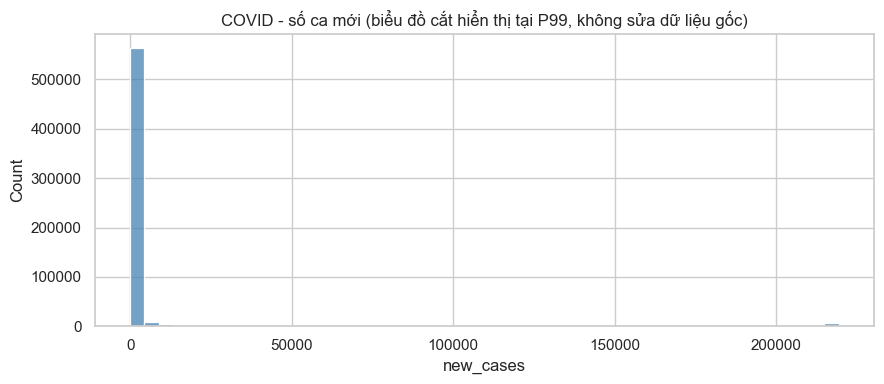

In [3]:
path = get_source('covid')
if path is not None:
    cols=['iso_code','continent','location','date','total_cases','new_cases']
    covid = pd.read_csv(path, usecols=lambda col: col in cols, low_memory=False)
    print('COVID shape:',covid.shape,'| cột:',covid.columns.tolist())
    if 'new_cases' in covid:
        display(descriptive_table(covid['new_cases']))
        print('Số new_cases âm:', (pd.to_numeric(covid['new_cases'],errors='coerce')<0).sum())
        v=pd.to_numeric(covid['new_cases'],errors='coerce').dropna()
        fig,ax=plt.subplots(figsize=(9,4));sns.histplot(v.clip(upper=v.quantile(.99)),bins=50,ax=ax,color='steelblue')
        ax.set_title('COVID - số ca mới (biểu đồ cắt hiển thị tại P99, không sửa dữ liệu gốc)')
        fig.tight_layout();fig.savefig(FIG_DIR/'eda_covid_hist.png',dpi=150);plt.show()
else: print('Bỏ qua COVID: cần CSV và/hoặc Internet.')

### A2. Bài mẫu Marketing: trùng lặp, Income thiếu, Teenhome, kiểu dữ liệu

Kiểm tra trước/sau các bước; không thay thế `Income` thiếu bằng 0 trong báo cáo kết quả vì 0 sẽ kéo trung bình xuống và làm sai ý nghĩa thu nhập. PDF có minh họa `fillna(0)` và `astype(int)` để luyện thao tác; đây chỉ là **minh họa cú pháp**, không nên coi 0 là thu nhập thật khi không có cơ sở. Mọi phép `drop` muốn lưu phải gán lại (hoặc `inplace=True`).

Đang dùng tệp: C:\Users\Admin\MLGroup\Tuan05\PTKPDL\data\marketing_campaign.csv
marketing shape: (2240, 11)
Trùng lặp nguyên dòng: 0
Số Income thiếu: 24


,So gia tri thieu
ID,0
Year_Birth,0
Education,0
Marital_Status,0
Income,24
Kidhome,0
Teenhome,0
Dt_Customer,0
Recency,0
NumStorePurchases,0


,Chỉ số,Giá trị
0,Số dòng,2.240000e+03
1,Số hợp lệ,2.216000e+03
2,Số thiếu / không chuyển thành số,2.400000e+01
3,Mean,5.224725e+04
4,Median (Q2),5.138150e+04
5,Mode đầu tiên,7.500000e+03
6,Variance mẫu,6.336838e+08
7,Std mẫu,2.517308e+04
8,Min,1.730000e+03
9,Max,6.666660e+05


Minh họa PDF (chỉ để học thao tác, KHÔNG thay dữ liệu gốc):
Số dòng sau dropna: 2216 | sau drop_duplicates: 2240


,Income,Income_filled_zero,Income_changed,Teenhome_replaced
0,58138.0,58138.0,58138,has no teen
1,46344.0,46344.0,46344,has teen
2,71613.0,71613.0,71613,has no teen
3,26646.0,26646.0,26646,has no teen
4,58293.0,58293.0,58293,has no teen


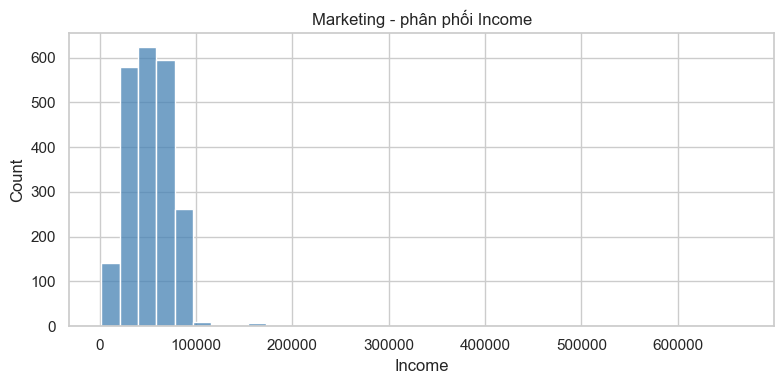

In [4]:
path=get_source('marketing')
if path is not None:
    marketing=read_separated_csv(path)
    selected=['ID','Year_Birth','Education','Marital_Status','Income','Kidhome','Teenhome',
              'Dt_Customer','Recency','NumStorePurchases','NumWebVisitsMonth']
    missing_cols = [v for v in selected if v not in marketing.columns]
    if missing_cols: raise ValueError(f'Thiếu cột Marketing: {missing_cols}; các cột hiện có: {marketing.columns.tolist()}')
    marketing = marketing[selected].copy()
    print('marketing shape:',marketing.shape)
    print('Trùng lặp nguyên dòng:',marketing.duplicated().sum())
    print('Số Income thiếu:',marketing['Income'].isna().sum())
    marketing_clean=marketing.drop_duplicates().copy()
    marketing_clean['Teenhome_replaced']=marketing_clean['Teenhome'].replace({0:'has no teen',1:'has teen',2:'has teen'})
    marketing_clean['Income_imputed_median']=marketing_clean['Income'].fillna(marketing_clean['Income'].median())
    marketing_clean['Dt_Customer']=pd.to_datetime(marketing_clean['Dt_Customer'],dayfirst=True,errors='coerce')
    display(marketing_clean.isna().sum().to_frame('So gia tri thieu'))
    display(descriptive_table(marketing_clean['Income']))
    print('Minh họa PDF (chỉ để học thao tác, KHÔNG thay dữ liệu gốc):')
    marketing_pdf_example = marketing_clean.copy()
    marketing_pdf_example['Income_filled_zero'] = marketing_pdf_example['Income'].fillna(0)
    marketing_pdf_example['Income_changed'] = marketing_pdf_example['Income_filled_zero'].astype('int64')
    print('Số dòng sau dropna:', len(marketing_clean.dropna()), '| sau drop_duplicates:', len(marketing_clean))
    display(marketing_pdf_example[['Income','Income_filled_zero','Income_changed','Teenhome_replaced']].head())
    fig,ax=plt.subplots(figsize=(8,4));sns.histplot(marketing_clean['Income'].dropna(),bins=35,ax=ax,color='steelblue')
    ax.set_title('Marketing - phân phối Income');fig.tight_layout();fig.savefig(FIG_DIR/'eda_marketing_income.png',dpi=150);plt.show()
else: print('Bỏ qua Marketing: cần CSV và/hoặc Internet.')

### A3. Bài tập Wine Quality: thống kê biến alcohol, volatile acidity, quality

`quality` là điểm chất lượng theo thang bậc nên xem tần suất từng điểm bên cạnh mean/median. Giá trị độ axit, nồng độ cồn có thể có ngoại lai; đánh giá quy trình đo lường trước khi loại bỏ.

Đang dùng tệp: C:\Users\Admin\MLGroup\Tuan05\PTKPDL\data\winequality-red.csv
Wine shape: (1599, 12) ; null: 0


,count,mean,std,min,25%,50%,75%,max
fixed acidity,1599.0,8.320,1.741,4.600,7.100,7.900,9.200,15.900
volatile acidity,1599.0,0.528,0.179,0.120,0.390,0.520,0.640,1.580
citric acid,1599.0,0.271,0.195,0.000,0.090,0.260,0.420,1.000
residual sugar,1599.0,2.539,1.410,0.900,1.900,2.200,2.600,15.500
chlorides,1599.0,0.087,0.047,0.012,0.070,0.079,0.090,0.611
free sulfur dioxide,1599.0,15.875,10.460,1.000,7.000,14.000,21.000,72.000
total sulfur dioxide,1599.0,46.468,32.895,6.000,22.000,38.000,62.000,289.000
density,1599.0,0.997,0.002,0.990,0.996,0.997,0.998,1.004
pH,1599.0,3.311,0.154,2.740,3.210,3.310,3.400,4.010
sulphates,1599.0,0.658,0.170,0.330,0.550,0.620,0.730,2.000


--- quality


,Chỉ số,Giá trị
0,Số dòng,1599.000000
1,Số hợp lệ,1599.000000
2,Số thiếu / không chuyển thành số,0.000000
3,Mean,5.636023
4,Median (Q2),6.000000
5,Mode đầu tiên,5.000000
6,Variance mẫu,0.652168
7,Std mẫu,0.807569
8,Min,3.000000
9,Max,8.000000


--- alcohol


,Chỉ số,Giá trị
0,Số dòng,1599.000000
1,Số hợp lệ,1599.000000
2,Số thiếu / không chuyển thành số,0.000000
3,Mean,10.422983
4,Median (Q2),10.200000
5,Mode đầu tiên,9.500000
6,Variance mẫu,1.135647
7,Std mẫu,1.065668
8,Min,8.400000
9,Max,14.900000


--- volatile acidity


,Chỉ số,Giá trị
0,Số dòng,1599.000000
1,Số hợp lệ,1599.000000
2,Số thiếu / không chuyển thành số,0.000000
3,Mean,0.527821
4,Median (Q2),0.520000
5,Mode đầu tiên,0.600000
6,Variance mẫu,0.032062
7,Std mẫu,0.179060
8,Min,0.120000
9,Max,1.580000


Đã xuất bảng: tv4_figures\eda_wine_descriptive.csv
Phân phối quality:


,so_luong
quality,
3,10
4,53
5,681
6,638
7,199
8,18


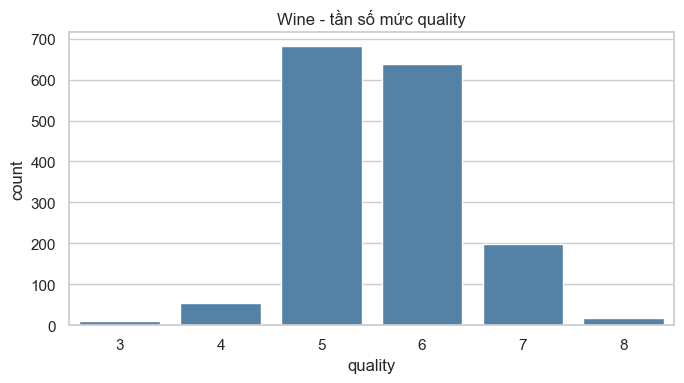

In [5]:
path=get_source('wine')
if path is not None:
    wine=read_separated_csv(path)
    if not {'quality', 'alcohol', 'volatile acidity'}.issubset(wine.columns):
        raise ValueError('Wine CSV không đúng cấu trúc: cần các cột quality, alcohol, volatile acidity. Hãy tải đúng winequality-red.csv từ UCI.')
    print('Wine shape:',wine.shape,'; null:',int(wine.isna().sum().sum()))
    display(wine.describe().T.round(3))
    for col in ['quality','alcohol','volatile acidity']:
        if col in wine.columns:
            print('---',col);display(descriptive_table(wine[col]))
    numeric_features = wine.select_dtypes(include='number').columns
    if len(numeric_features):
        summary = pd.DataFrame({col: descriptive_table(wine[col]).set_index('Chỉ số')['Giá trị'] for col in numeric_features}).T
        summary.to_csv(FIG_DIR/'eda_wine_descriptive.csv',encoding='utf-8-sig')
        print('Đã xuất bảng:', FIG_DIR/'eda_wine_descriptive.csv')
    if 'quality' in wine.columns:
        print('Phân phối quality:');display(wine['quality'].value_counts().sort_index().to_frame('so_luong'))
        fig,ax=plt.subplots(figsize=(7,4));sns.countplot(data=wine,x='quality',ax=ax,color='steelblue')
        ax.set_title('Wine - tần số mức quality');fig.tight_layout();fig.savefig(FIG_DIR/'eda_wine_quality.png',dpi=150);plt.show()
else: print('Bỏ qua Wine: cần CSV và/hoặc Internet.')

### A4. Bài tập Pima Diabetes: kiểm tra biến đo lường bằng 0

Trong bộ dữ liệu Pima thông dụng, số 0 của `Glucose`, `BloodPressure`, `SkinThickness`, `Insulin`, `BMI` có khả năng biểu thị phép đo bị thiếu/không hợp lệ; không coi số 0 ở `Pregnancies` là bị thiếu. Báo cáo nhóm cung cấp mốc đối chiếu **Insulin = 0 ở 374 dòng**; notebook tính trực tiếp để kiểm chứng.

Đang dùng tệp: C:\Users\Admin\MLGroup\Tuan05\PTKPDL\data\diabetes.csv
Pima shape: (768, 9)


,so_zero_nghi_ngo_thieu
Insulin,374
SkinThickness,227
BloodPressure,35
BMI,11
Glucose,5


Tỷ lệ nhãn Outcome: {0: 0.651, 1: 0.349}


,count,mean,std,min,25%,50%,75%,max
Pregnancies,768.0,3.845,3.370,0.000,1.000,3.000,6.000,17.00
Glucose,768.0,120.895,31.973,0.000,99.000,117.000,140.250,199.00
BloodPressure,768.0,69.105,19.356,0.000,62.000,72.000,80.000,122.00
SkinThickness,768.0,20.536,15.952,0.000,0.000,23.000,32.000,99.00
Insulin,768.0,79.799,115.244,0.000,0.000,30.500,127.250,846.00
BMI,768.0,31.993,7.884,0.000,27.300,32.000,36.600,67.10
DiabetesPedigreeFunction,768.0,0.472,0.331,0.078,0.244,0.372,0.626,2.42
Age,768.0,33.241,11.760,21.000,24.000,29.000,41.000,81.00
Outcome,768.0,0.349,0.477,0.000,0.000,0.000,1.000,1.00


,missing_sau_chuyen_0
Pregnancies,0
Glucose,5
BloodPressure,35
SkinThickness,227
Insulin,374
BMI,11
DiabetesPedigreeFunction,0
Age,0
Outcome,0


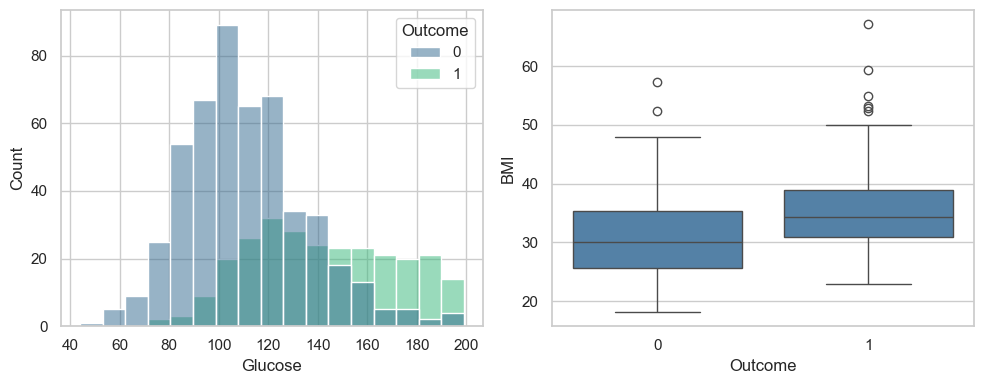

In [6]:
path=get_source('diabetes')
if path is not None:
    pima=read_separated_csv(path)
    print('Pima shape:',pima.shape)
    required=['Glucose','BloodPressure','SkinThickness','Insulin','BMI','Outcome']
    if not set(required).issubset(pima.columns): raise ValueError(f'CSV Pima thiếu cột: {sorted(set(required)-set(pima.columns))}')
    invalid_zero=['Glucose','BloodPressure','SkinThickness','Insulin','BMI']
    counts=(pima[invalid_zero]==0).sum().sort_values(ascending=False)
    display(counts.to_frame('so_zero_nghi_ngo_thieu'))
    print('Tỷ lệ nhãn Outcome:',pima['Outcome'].value_counts(normalize=True).round(4).to_dict())
    display(pima.describe().T.round(3))
    pima_for_eda=pima.copy();pima_for_eda[invalid_zero]=pima_for_eda[invalid_zero].replace(0,np.nan)
    display(pima_for_eda.isna().sum().to_frame('missing_sau_chuyen_0'))
    pima_for_eda.describe().T.to_csv(FIG_DIR/'eda_diabetes_descriptive.csv',encoding='utf-8-sig')
    fig,axes=plt.subplots(1,2,figsize=(10,4))
    sns.histplot(data=pima_for_eda,x='Glucose',hue='Outcome',multiple='layer',ax=axes[0],palette='viridis')
    sns.boxplot(data=pima_for_eda,x='Outcome',y='BMI',ax=axes[1],color='steelblue')
    fig.tight_layout();fig.savefig(FIG_DIR/'eda_pima_summary.png',dpi=150);plt.show()
else: print('Bỏ qua Pima: cần CSV và/hoặc Internet.')

## Kiểm tra khi nộp phần EDA
- Chỉ dùng thống kê xuất từ **dữ liệu đã tải**; không coi `Income=0` hoặc `Insulin=0` là dữ liệu đúng nếu chưa kiểm tra.
- Theo số liệu nhóm đang sử dụng, bộ Pima thông dụng có **374** giá trị `Insulin=0`; hãy đối chiếu với kết quả từ `counts` ở trên.
- Các tệp hình lưu trong `tv4_figures`. Nếu nguồn CSV khác bản thầy/nhóm, ghi rõ số dòng, ngày lấy dữ liệu và phiên bản.